# Tutorial 3 — Data compression

Notebook of the programming section of chapter 3 of R. Kühn, P. Vivo and F. Zamponi,
*Introduction to statistical physics for non-physicists* (Oxford University Press).
The appendix computes the entropy of English used in the tutorial of the same chapter.

**How to run it.** Run all cells from top to bottom.
* *Locally (Jupyter):* run it from its folder; it needs the packages `zstandard` (version 0.23.0, because
  the size of the compressed files depends on the version) and `bitarray`.
* *On Google Colab:* [open it in Colab](https://colab.research.google.com/github/francescozamponi/statphys-tutorials/blob/main/Tutorial_3/Tutorial_3.ipynb)
  and run all cells; the packages and the data files are installed and downloaded automatically.

The random number generator is seeded, so that the notebook reproduces the figures and numbers of the book.

In [2]:
import os, sys, subprocess, urllib.request, importlib.metadata
IN_COLAB = 'google.colab' in sys.modules

# Packages: zstandard is pinned, because the size of the compressed files depends on its version
REQUIRED = {'zstandard': '0.23.0', 'bitarray': None}
for pkg, ver in REQUIRED.items():
    try:
        installed = importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed is None or (ver and installed != ver):
        if IN_COLAB or installed is None:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', f'{pkg}=={ver}' if ver else pkg], check=True)
        else:
            print(f'Warning: {pkg} {installed} is installed; the book uses {pkg} {ver} '
                  f'(pip install {pkg}=={ver}), so the compressed sizes may differ slightly.')

import numpy as np
import math
import matplotlib.pyplot as plt
import scipy as sp
import scipy.stats
import zlib
import bz2
import gzip
import io
import zstandard as zstd
from bitarray import bitarray

import logging
logging.getLogger('fontTools').setLevel(logging.ERROR)

%matplotlib inline
print('zstandard', importlib.metadata.version('zstandard'))

# Book repository, from which missing data files are downloaded
BOOK_REPO = 'https://raw.githubusercontent.com/francescozamponi/statphys-tutorials/main/'
FOLDER = 'Tutorial_3/'

def get_data(fname, sources=()):
    """Return fname if it is in the working folder; otherwise try to download it from the
    book repository and from `sources`; on Colab, as a last resort, ask to upload it."""
    if os.path.exists(fname):
        return fname
    for url in [BOOK_REPO + FOLDER + fname] + list(sources):
        try:
            urllib.request.urlretrieve(url, fname)
            print('downloaded', fname, 'from', url)
            return fname
        except Exception:
            pass
    if IN_COLAB:
        from google.colab import files
        print(f'Please upload {fname}')
        files.upload()
        if os.path.exists(fname):
            return fname
    raise FileNotFoundError(f'{fname} not found: download it into the folder of this notebook')

# Book formatting: every figure is saved at its printed size, so that all text prints at the
# same size in the book (bookfig.py; it does not change the plots). Without bookfig.py the
# figures are saved as they are.
sys.path[:0] = ['..', '../Figs_generator']
try:
    from bookfig import setup, save, HALF, SINGLE, FULL
except ImportError:                         # e.g. on Colab: fetch bookfig.py from the book repository
    try:
        urllib.request.urlretrieve(BOOK_REPO + 'bookfig.py', 'bookfig.py')
        from bookfig import setup, save, HALF, SINGLE, FULL
    except Exception:
        setup = None
if setup:
    setup()
else:
    HALF, SINGLE, FULL = 0.49, 0.7, 1.0
    def save(path, width, **kw):
        plt.savefig(path, bbox_inches='tight')

np.random.seed(0)   # fixed seed: reproduces the run shown in the book

zstandard 0.23.0


## Question 1: compressing the four files

The files `uniform.txt`, `half.txt`, `abcd.txt` and `abcd2.txt` contain $10^4$ ASCII characters each,
drawn from the distributions given in the book. We compress them with the same algorithms as the
command-line programs `gzip` (default level 6, which also stores the file name in the compressed file)
and `bzip2` (default level 9), and compare the compression ratio $R$ with the ideal one, $H[X]/8$.

In [4]:
def gzip_size(data, name):
    buf = io.BytesIO()
    with gzip.GzipFile(filename=name, mode='wb', fileobj=buf, compresslevel=6, mtime=0) as f:
        f.write(data)
    return len(buf.getvalue())

H = {'uniform.txt': 8, 'half.txt': 7, 'abcd.txt': 2, 'abcd2.txt': 7/4}   # entropy in bits per character
print(f"{'file':12s} {'size':>6s} {'gzip':>6s} {'bzip2':>6s} {'R (bzip2)':>10s} {'R (ideal)':>10s}")
for name, h in H.items():
    data = open(get_data(name), 'rb').read()
    b = len(bz2.compress(data, 9))
    print(f'{name:12s} {len(data):6d} {gzip_size(data, name):6d} {b:6d} {b/len(data):10.4f} {h/8:10.5f}')

file           size   gzip  bzip2  R (bzip2)  R (ideal)
uniform.txt   10000  10035  10469     1.0469    1.00000
half.txt      10000   8848   9021     0.9021    0.87500
abcd.txt      10000   3228   2815     0.2815    0.25000
abcd2.txt     10000   2913   2660     0.2660    0.21875


## Generate a random sequence with given probabilities

In [6]:
# Generate sequence of numbers
def generate_random_seq(L,P):
  q=len(P)
  rseq=[]
  for i in range(L):
    rseq.append(np.random.choice(q,p=P))
  # Convert the list of characters to an ASCII-encoded bytes object
  return rseq

# Convert to a list of characters
def to_alphabet(rseq,alphabet):
    return [alphabet[i] for i in rseq]

# Convert to ascii
def to_ascii(rseq):
  ascii_bytes = bytes(''.join(rseq), encoding='ascii')
  return ascii_bytes


In [7]:
S=generate_random_seq(10000,[1/4,1/8,1/4,1/8,1/8,1/8])
Sa=to_alphabet(S,['A','B','C','D','E','F'])
Sb=to_ascii(Sa)
L=len(Sb)
print("Sequence length:",L)
print("#bits/symbol:",sys.getsizeof(Sb)*8/L)
np.savetxt("random_seq.txt",Sa,fmt='%s',delimiter='',newline='')

Sequence length: 10000
#bits/symbol: 8.0264


## Check the compression rate

In [9]:
Scc = zlib.compress(Sb)
print("Compressed sequence, #bits/symbol:",sys.getsizeof(Scc)*8/L)
print("R:",sys.getsizeof(Scc)/sys.getsizeof(Sb))

Compressed sequence, #bits/symbol: 3.1776
R: 0.39589355128077347


In [10]:
Scc = bz2.compress(Sb)
print("Compressed sequence, #bits/symbol:",sys.getsizeof(Scc)*8/L)
print("R:",sys.getsizeof(Scc)/sys.getsizeof(Sb))

Compressed sequence, #bits/symbol: 2.8256
R: 0.3520382736968006


In [11]:
compressor = zstd.ZstdCompressor()
Scc = compressor.compress(Sb)
print("Compressed sequence, #bits/symbol:",sys.getsizeof(Scc)*8/L)
print("R:",sys.getsizeof(Scc)/sys.getsizeof(Sb))

Compressed sequence, #bits/symbol: 3.1992
R: 0.3985846705870627


## Make the histogram

In [13]:
M=1000
K = []
compressor = zstd.ZstdCompressor()
for i in range(M):
    S=generate_random_seq(10000,[1/4,1/8,1/4,1/8,1/8,1/8])
    Sa=to_alphabet(S,['A','B','C','D','E','F'])
    Sb=to_ascii(Sa)
    Scc = compressor.compress(Sb)
    L=sys.getsizeof(Scc)*8
    K.append(L)
    if (i%100==0):
        print(i)

0
100
200
300
400
500
600
700
800
900


400


500


600


700


800


900


In [14]:
print(np.mean(K), np.std(K))

32076.992 76.41596649915515


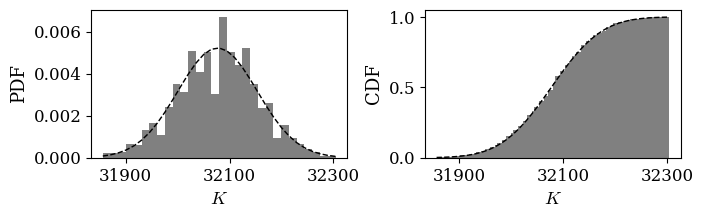

In [15]:
fig, ((ax1, ax3)) = plt.subplots(nrows=1, ncols=2, figsize=(20,6))

n, bins, patches = ax1.hist(K, bins=30, facecolor='grey',density=True);
ax1.set_xlabel('$K$')
ax1.set_ylabel('PDF')
ax1.set_xticks([31900, 32100, 32300])
ax1.plot(bins, sp.stats.norm.pdf(bins, loc=np.mean(K), scale=np.std(K)), '--', color ='black', linewidth=3)

n, bins, patches = ax3.hist(K, bins=100, facecolor='grey',density=True,cumulative=True);
ax3.set_xlabel('$K$')
ax3.set_ylabel('CDF')
ax3.set_xticks([31900, 32100, 32300])
ax3.plot(bins, sp.stats.norm.cdf(bins, loc=np.mean(K), scale=np.std(K)), '--', color ='black', linewidth=3)

plt.tight_layout()
save("hist-zstd.pdf", FULL)

plt.show()


## Write our own compression code

In [17]:
d = {'A':bitarray('10'), 'B':bitarray('000'), 'C':bitarray('11'), 'D':bitarray('001'), 'E':bitarray('010'), 'F':bitarray('011')}

In [18]:
S=generate_random_seq(10000,[1/4,1/8,1/4,1/8,1/8,1/8])
Sa=to_alphabet(S,['A','B','C','D','E','F'])
#Sb=convert_to_bitarray(Sa)
Sb = bitarray()
Sb.encode(d, Sa)
L=len(Sb)
print("Sequence length:",L)

Sequence length: 24973


In [19]:
M=1000
K = []
for i in range(M):
    S=generate_random_seq(10000,[1/4,1/8,1/4,1/8,1/8,1/8])
    Sa=to_alphabet(S,['A','B','C','D','E','F'])
    Sb = bitarray()
    Sb.encode(d, Sa)
    L=len(Sb)
    K.append(L)
    if (i%100==0):
        print(i)

0
100
200
300
400
500
600
700
800
900


300


400


500


600


700


800


900


In [20]:
print(np.mean(K), np.std(K))

24996.692 49.35462628771491


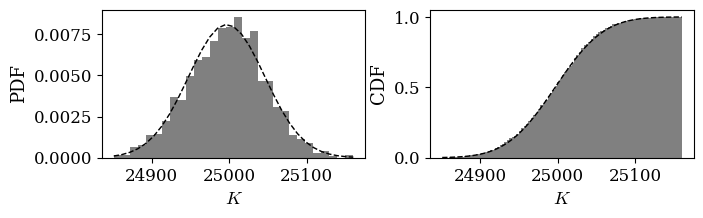

In [21]:
fig, ((ax1, ax3)) = plt.subplots(nrows=1, ncols=2, figsize=(20,6))

n, bins, patches = ax1.hist(K, bins=30, facecolor='grey',density=True);
ax1.set_xlabel('$K$')
ax1.set_ylabel('PDF')
ax1.plot(bins, sp.stats.norm.pdf(bins, loc=np.mean(K), scale=np.std(K)), '--', color ='black', linewidth=3)

n, bins, patches = ax3.hist(K, bins=100, facecolor='grey',density=True,cumulative=True);
ax3.set_xlabel('$K$')
ax3.set_ylabel('CDF')
ax3.plot(bins, sp.stats.norm.cdf(bins, loc=np.mean(K), scale=np.std(K)), '--', color ='black', linewidth=3)

plt.tight_layout()
save("hist-bitarray.pdf", FULL)

plt.show()


# APPENDIX: THE ENTROPY OF ENGLISH

Tutorial of chapter 3, question 4. Frequencies (in %) of the 26 letters in English texts, from
[Wikipedia](https://en.wikipedia.org/wiki/Letter_frequency). They are rounded, so they sum to
100.119% rather than 100%: we normalise them before computing the entropy $H$ (in bits per letter)
and the compression ratios with respect to a uniform distribution over the 26 letters,
$R_{26} = H/\log_2 26$, and with respect to an ASCII encoding, $R_\text{ASCII} = H/\log_2 256$.

In [23]:
p = np.array([8.2, 1.5, 2.8, 4.3, 12.7, 2.2, 2.0, 6.1, 7.0, 0.15, 0.77, 4.0, 2.4,
              6.7, 7.5, 1.9, 0.095, 6.0, 6.3, 9.1, 2.8, 0.98, 2.4, 0.15, 2.0, 0.074])   # a, b, ..., z
print(len(p), 'letters; sum of the frequencies:', p.sum(), '%')
p = p / p.sum()
H = -(p * np.log2(p)).sum()
print(f'H = {H:.3f} bits per letter')
print(f'R_26 = H/log2(26) = {H/np.log2(26):.3f}')
print(f'R_ASCII = H/log2(256) = {H/np.log2(256):.3f}')

26 letters; sum of the frequencies: 100.11899999999999 %
H = 4.176 bits per letter
R_26 = H/log2(26) = 0.888
R_ASCII = H/log2(256) = 0.522
